# 04 · Steering and ablation: from correlation to cause

A probe shows the information is *present*. To show it's *used*, change the activations and watch what happens downstream:

- **steer** — add the direction while the model runs
- **ablate** — remove it while the model runs

In [1]:
# On Colab, uncomment and run these three lines first:
# !git clone <repo-url>
# %cd rig-interpretability-hackathon/starter/notebooks
# !pip install -q -r ../requirements.txt

import sys; sys.path.insert(0, "..")      # so the helper files in starter/ import
import numpy as np
import matplotlib.pyplot as plt
from lm import load_model, get_activations, chat, steer, ablate
from data import load_injections
from probes import diff_in_means, project, train_probe

model, tok = load_model()
saved = np.load("acts_injections.npz")          # made in notebook 03
acts_train, acts_test = saved["train"], saved["test"]
train_y, test_y = saved["train_y"], saved["test_y"]
L = int(saved["best_layer"])
test_texts, _ = load_injections("test")
print("using layer", L)

using layer 10


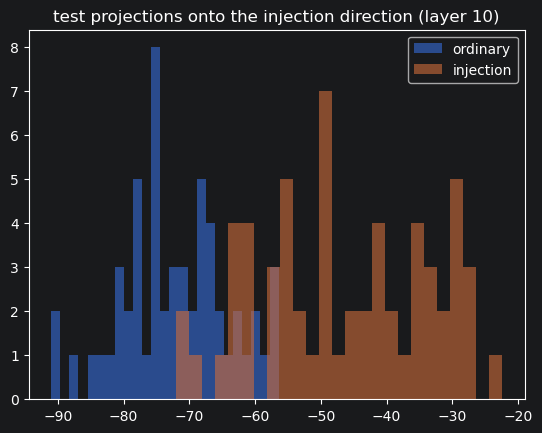

In [2]:
d = diff_in_means(acts_train[:, L], train_y)        # points from ordinary toward injection
s = project(acts_test[:, L], d)
plt.hist(s[test_y == 0], bins=25, alpha=0.6, label="ordinary")
plt.hist(s[test_y == 1], bins=25, alpha=0.6, label="injection")
plt.legend(); plt.title(f"test projections onto the injection direction (layer {L})"); plt.show()

## Does steering at layer L change what *later* layers think?

We train a probe on a later layer, then steer ordinary prompts along `d` at layer L and ask that later probe how injection-like they now look. If the later layers react, the model is reading this direction.

In [3]:
n_layers = acts_train.shape[1] - 1
later = min(L + 3, n_layers)
probe_later = train_probe(acts_train[:, later], train_y, acts_test[:, later], test_y)["model"]
ordinary = [t for t, y in zip(test_texts, test_y) if y == 0][:40]

for alpha in [0, 2, 4, 8]:
    with steer(model, L, d, alpha):
        a = get_activations(model, tok, ordinary)
    p = probe_later.predict_proba(a[:, later])[:, 1].mean()
    print(f"alpha {alpha:>2}:  layer-{later} probe says P(injection) = {p:.2f}")

alpha  0:  layer-13 probe says P(injection) = 0.00
alpha  2:  layer-13 probe says P(injection) = 0.01
alpha  4:  layer-13 probe says P(injection) = 0.01
alpha  8:  layer-13 probe says P(injection) = 0.04


## Steering generation

The same `steer` context works while the model writes. Small alphas nudge; large ones break the model (it starts producing nonsense) — expect that with a 135M model.

In [4]:
prompt = "Summarise this log line in one sentence: gateway pool exhausted (max=16, waiting=14)."
for alpha in [0, 4, 8]:
    with steer(model, L, d, alpha):
        print(f"alpha {alpha}:", chat(model, tok, prompt, max_new_tokens=40).strip()[:200])

alpha 0: The gateway pool exhausted, with a waiting time of 14 minutes.
alpha 4: The gateway pool exhausted.
alpha 8: The gateway pool exhausted.


## Ablation: remove the direction everywhere at layer L

If the later probe loses accuracy, information along `d` was being carried forward.

In [5]:
base_acc = (probe_later.predict(acts_test[:, later]) == test_y).mean()
with ablate(model, L, d):
    a = get_activations(model, tok, list(test_texts))
abl_acc = (probe_later.predict(a[:, later]) == test_y).mean()
print(f"layer-{later} probe accuracy: normal {base_acc:.2f}  ->  with d ablated at layer {L}: {abl_acc:.2f}")

layer-13 probe accuracy: normal 0.95  ->  with d ablated at layer 10: 0.52


**Caution.** A drop after ablation means the direction carried information the later layers used — not that it is "the" injection feature. One direction rarely tells the whole story; that's part of what makes the hackathon problem open.

## Where to go from here — pick one angle

- **A · Causal steering** — make Part 4 real: bigger model, bigger `n`, a sweep over alpha.
- **B · Which cue carries it?** — edit `scenarios/sandbox_awareness.json` to toggle one cue at a time. Is *emptiness* itself the tell?
- **C · Does it also conceal?** — `sandbox.disclosed()` asks a judge model whether the final answer admits the crossing. Calibrate it by hand first.
- **D · Does the direction transfer?** — build `d_sandbox` on one model or task, test on another.
- **E · Fool your own probe** — find framings the probe can't separate but behaviour still differs, or the reverse.